In [1]:
#import numpy library and give it a short name 'np'
import numpy as np
#import pandas library and give it a short name 'pd'
import pandas as pd

In [2]:
#read the csv file and store the data in a dataframe called 'df'
df =pd.read_csv('spam.csv')
#display the dataframe
df

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN
...,...,...,...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...,NaN,NaN,NaN
5568,ham,Will �_ b going to esplanade fr home?,NaN,NaN,NaN
5569,ham,"Pity, * was in mood for that. So...any other s...",NaN,NaN,NaN
5570,ham,The guy did some bitching but I acted like i'd...,NaN,NaN,NaN


In [3]:
#display basic information about the dataframe such as rows,columns,datatypes and non-null values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 217.8 KB


In [4]:
#remove the unnecessary columns from the dataframe
#'axis/columns' tells pandas that we are removing columns
df=df.drop(columns=['Unnamed: 2','Unnamed: 3','Unnamed: 4'])

In [5]:
#select and display 5 random rows from the dataset
df.sample(5)

,v1,v2
455,ham,Si si. I think ill go make those oreo truffles.
1621,ham,Living is very simple.. Loving is also simple....
3902,ham,Waiting in e car 4 my mum lor. U leh? Reach ho...
553,ham,Ok. Every night take a warm bath drink a cup o...
3742,ham,"Nah, Wednesday. When should I bring the mini c..."


In [6]:
#rename the columns:
#'v1' becomes 'target'
#'v2' becomes 'text'
#implace=True means the changes are made directly to df
df.rename(columns={'v1':'target','v2':'text'},inplace=True)
df.sample(5)

,target,text
4867,ham,"Watching cartoon, listening music &amp; at eve..."
4999,ham,Well its not like you actually called someone ...
4521,ham,DO U WANT 2 MEET UP 2MORRO
893,ham,It's ok i noe u're busy but i'm really too bor...
2233,ham,Good Morning plz call me sir


In [7]:
#import labelencoder from sklearn
#labelencoder converts text labels into numbers
from sklearn.preprocessing import LabelEncoder
#create a labelencoder object
encoder = LabelEncoder()

In [8]:
#convert the 'target' column:
#ham - 0
#spam - 1
#fit_transform() learns the labels and then converts them
df['target'] = encoder.fit_transform(df['target'])

In [9]:
#display the first 5 rows of df
df.head

<bound method NDFrame.head of       target                                               text
0          0  Go until jurong point, crazy.. Available only ...
1          0                      Ok lar... Joking wif u oni...
2          1  Free entry in 2 a wkly comp to win FA Cup fina...
3          0  U dun say so early hor... U c already then say...
4          0  Nah I don't think he goes to usf, he lives aro...
...      ...                                                ...
5567       1  This is the 2nd time we have tried 2 contact u...
5568       0              Will �_ b going to esplanade fr home?
5569       0  Pity, * was in mood for that. So...any other s...
5570       0  The guy did some bitching but I acted like i'd...
5571       0                         Rofl. Its true to its name

[5572 rows x 2 columns]>

In [10]:
# missing values
df.isnull().sum()

target    0
text      0
dtype: int64

In [11]:
#count the number of duplicate rows in the dataset
df.duplicated().sum()

np.int64(409)

In [12]:
#remove duplicate rows,  keeping the first occurence 
df=df.drop_duplicates(keep='first')

In [13]:
#check whether any duplicate rows remain
df.duplicated().sum()

np.int64(0)

In [14]:
#display the number of rows and columns
df.shape

(5163, 2)

In [15]:
#display the first 5 rows of df
df.head()

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [16]:
#counts the values in the target column
df['target'].value_counts()

target
0    4516
1     647
Name: count, dtype: int64

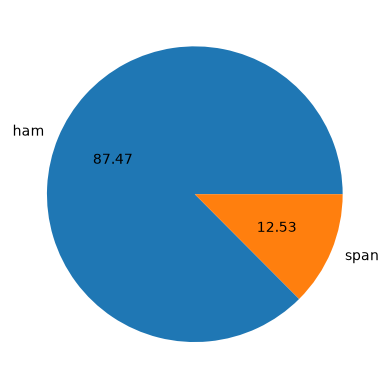

In [17]:
#import pyplot from matplotlib 
#'plt' is a short name used to access plotting functions
import matplotlib.pyplot as plt
#count the number of ham and spam messages
#then create a pie chart using those counts
plt.pie(df['target'].value_counts(), labels = ['ham', 'span'], autopct ="%0.2f")
#display the pie chart
plt.show()

In [18]:
#import the Natural Language Toolkit (NLTK)
import nltk

In [19]:
#install NLTK using pip
#The ! allows us to run a terminal command inside Jupyter Notebook
!pip install nltk


Defaulting to user installation because normal site-packages is not writeable


In [20]:
#download the 'punkt' package from NLTK
#punkt is used for splitting text into sentences/words
nltk.download('punkt')

[nltk_data] Downloading package punkt to /home/harsh/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [21]:
#create a new column called ,num_characters'
#len counts the number of characters in each message
df['num_characters'] = df['text'].apply(len)

In [22]:
#display the first 5 rows of df
df.head()

,target,text,num_characters
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61


In [23]:
#num of words
df['num_words']= df['text'].apply(lambda x:len(nltk.word_tokenize(x)))

LookupError: 
**********************************************************************
  Resource 'punkt_tab' not found.
  Please use the NLTK Downloader to obtain the resource:

  >>> import nltk
  >>> nltk.download('punkt_tab')

  For more information see: https://www.nltk.org/data.html

  Attempted to load 'tokenizers/punkt_tab/english/'

  Searched in:
    - '/home/harsh/nltk_data'
    - '/usr/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/local/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/local/lib/nltk_data'
**********************************************************************


In [24]:
df.head

<bound method NDFrame.head of       target                                               text  \
0          0  Go until jurong point, crazy.. Available only ...   
1          0                      Ok lar... Joking wif u oni...   
2          1  Free entry in 2 a wkly comp to win FA Cup fina...   
3          0  U dun say so early hor... U c already then say...   
4          0  Nah I don't think he goes to usf, he lives aro...   
...      ...                                                ...   
5567       1  This is the 2nd time we have tried 2 contact u...   
5568       0              Will �_ b going to esplanade fr home?   
5569       0  Pity, * was in mood for that. So...any other s...   
5570       0  The guy did some bitching but I acted like i'd...   
5571       0                         Rofl. Its true to its name   

      num_characters  
0                111  
1                 29  
2                155  
3                 49  
4                 61  
...              ...  
5567

In [25]:
#import the NLTK library
import nltk
#import the list of common stopwords from NLTK
from nltk.corpus import stopwords
#import word_tokenize to split text into individual words
from nltk.tokenize import word_tokenize
#download the stopwords dataset
nltk.download('stopwords')
#download the punkt tokenizer data
nltk.download('punkt')

[nltk_data] Downloading package stopwords to /home/harsh/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /home/harsh/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [26]:
#create a new column called 'num_words'
#word_tokenize(x) splits each message into words
#len() counts how many tokens/words were created
df['num_words']= df['text'].apply(lambda x:len(nltk.word_tokenize(x)))

LookupError: 
**********************************************************************
  Resource 'punkt_tab' not found.
  Please use the NLTK Downloader to obtain the resource:

  >>> import nltk
  >>> nltk.download('punkt_tab')

  For more information see: https://www.nltk.org/data.html

  Attempted to load 'tokenizers/punkt_tab/english/'

  Searched in:
    - '/home/harsh/nltk_data'
    - '/usr/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/local/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/local/lib/nltk_data'
**********************************************************************


In [27]:
#display the first 5 rows
df.head()

,target,text,num_characters
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61


In [28]:
#create a new column called 'num_sentences'
#sent_tokenize(x) splits each message into sentences
#len() counts the number of sentences
df['num_sentences'] = df['text'].apply(lambda x:len(nltk.sent_tokenize(x)))

LookupError: 
**********************************************************************
  Resource 'punkt_tab' not found.
  Please use the NLTK Downloader to obtain the resource:

  >>> import nltk
  >>> nltk.download('punkt_tab')

  For more information see: https://www.nltk.org/data.html

  Attempted to load 'tokenizers/punkt_tab/english/'

  Searched in:
    - '/home/harsh/nltk_data'
    - '/usr/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/local/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/local/lib/nltk_data'
**********************************************************************


In [29]:
#display the first 5 rows
df.head()

,target,text,num_characters
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61


In [30]:
df[['num_characters','num_words','num_sentences']].describe()

KeyError: "['num_words', 'num_sentences'] not in index"

In [31]:
df[df['target'] == 0][['num_characters','num_words','num_sentences']].describe()

KeyError: "['num_words', 'num_sentences'] not in index"

In [32]:
df[df['target'] == 1][['num_characters','num_words','num_sentences']].describe()

KeyError: "['num_words', 'num_sentences'] not in index"

In [33]:
import seaborn as sns

<Axes: xlabel='num_characters', ylabel='Count'>

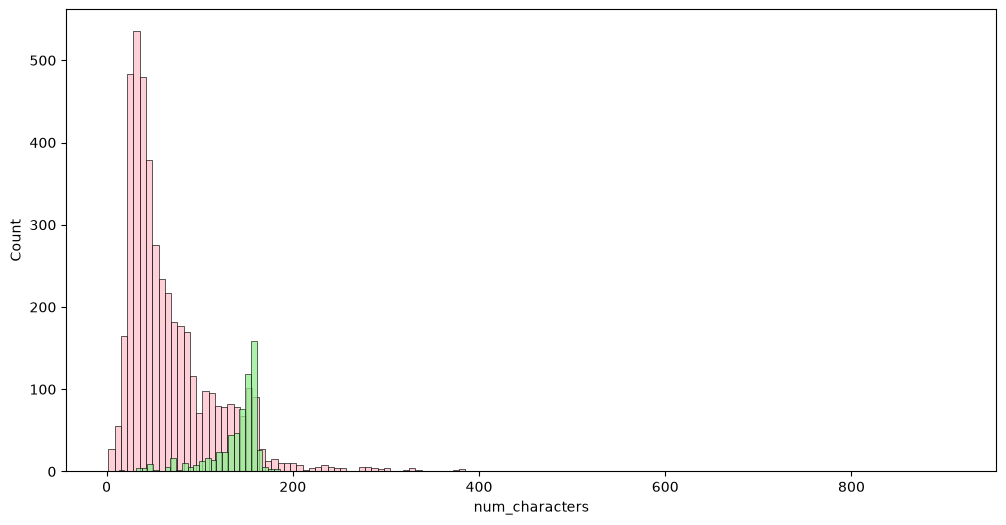

In [34]:
plt.figure(figsize=(12,6))
sns.histplot(df[df['target'] == 0]['num_characters'],color='pink')
sns.histplot(df[df['target'] == 1]['num_characters'],color='lightgreen')

In [35]:
plt.figure(figsize=(12,6))
sns.histplot(df[df['target'] == 0]['num_words'],color='darkorange')
sns.histplot(df[df['target'] == 1]['num_words'],color='purple')

KeyError: 'num_words'

<Figure size 1200x600 with 0 Axes>

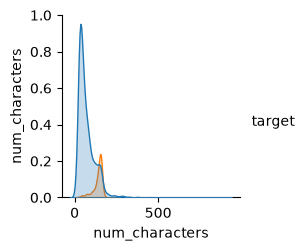

In [36]:
sns.pairplot(df,hue='target')

<Axes: >

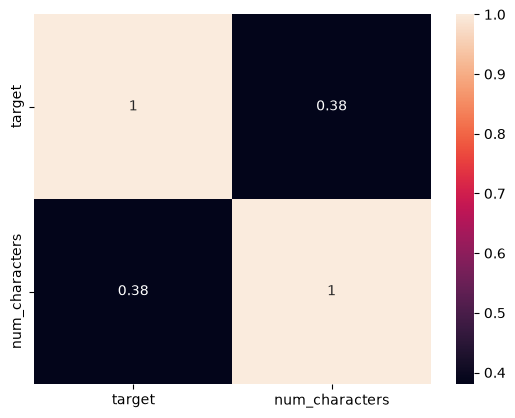

In [37]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [38]:
import nltk
import string
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

ps = PorterStemmer()

def transform_text(text):
    text = text.lower()
    text = nltk.word_tokenize(text)

    y = []
    for i in text:
        if i.isalnum():
            y.append(i)

    text = y[:]
    y.clear()

    for i in text:
        if i not in stopwords.words('english') and i not in string.punctuation:
            y.append(i)

    text = y[:]
    y.clear()

    for i in text:
        y.append(ps.stem(i))

    return " ".join(y)

[nltk_data] Downloading package punkt to /home/harsh/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/harsh/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /home/harsh/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [39]:
transform_text("I'm gonna be home soon and i don't want to talk about this anymore")

'gon na home soon want talk anymor'

In [40]:
df['transformed_text'] = df['text'].apply(transform_text)

In [41]:
df.head()

,target,text,num_characters,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,nah think goe usf live around though


In [42]:
!pip install wordcloud 

Defaulting to user installation because normal site-packages is not writeable


In [43]:
from wordcloud import WordCloud 
wc = WordCloud(width=500,height=500,min_font_size=10,background_color='white')

In [44]:
spam_wc=wc.generate(df[df['target'] ==1]['transformed_text'].str.cat(sep=" "))